<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_2%EC%A1%B0_Project2_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OB 2조 · 소설 작가 분류 — 베이스라인 모델

**목표**: 전처리·EDA 결과를 바탕으로 기본 머신러닝 모델을 만들고, 초기 성능(LogLoss)과 개선 방향을 정한다.

**흐름**
1. 데이터 불러오기 · 공통 설정 (같은 5-fold로 모든 모델 비교)
2. 벡터화 설정 비교 — 어떤 TF-IDF 설정이 점수를 바꾸는가
3. 모델 비교 — Logistic Regression / Naive Bayes (5-fold OOF)
4. 결과 분석 — 문장 길이별 성능, 작가별 혼동
5. 제출 파일 생성
6. 정리 및 개선 방향

> ⏱ 전체 실행 약 20~25분 (CPU 기준). 2번·3번 셀이 오래 걸립니다.

## 1. 데이터 불러오기 · 공통 설정

In [1]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/ESAA_OB/OB_data/Project(2)'

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss, accuracy_score, confusion_matrix

# 전처리및EDA 노트북에서 만든 파일
train = pd.read_csv(f'{DATA_DIR}/train_clean.csv')
test = pd.read_csv(f'{DATA_DIR}/test_clean.csv')

X_text = train['text_model'].fillna('')
T_text = test['text_model'].fillna('')
y = train['author'].values
print(train.shape, test.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(54739, 5) (19617, 4)


- 모델 입력은 EDA에서 정한 대로 **`text_model`** (소문자화·공백 정리만, 문장부호·불용어 유지)
- `train_clean.csv`가 없다는 에러가 나면: 전처리및EDA 노트북 마지막 저장 셀의 경로를 `f'{DATA_DIR}/train_clean.csv'`로 바꿔 다시 실행

In [2]:
# 모든 모델이 '같은 문제'를 풀도록 fold를 고정
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(skf.split(X_text, y))

# test와 비슷한 '긴 문장' (test는 최소 131자) — 실제 test 점수에 더 가까운 참고 지표
is_long = (train['text'].str.len() >= 131).values
print(f'131자 이상 문장: {is_long.sum()}개 ({is_long.mean():.1%})')

results, oofs = {}, {}
def record(name, oof):
    oofs[name] = oof
    results[name] = {
        'OOF LogLoss': log_loss(y, oof),
        'Accuracy': accuracy_score(y, oof.argmax(1)),
        'LogLoss (131자 이상)': log_loss(y[is_long], oof[is_long], labels=range(5)),
    }
    r = results[name]
    print(f"▶ {name}: LogLoss {r['OOF LogLoss']:.4f} / Acc {r['Accuracy']:.4f} / 긴 문장 LogLoss {r['LogLoss (131자 이상)']:.4f}")

def cv_oof(make_model, X, name):
    oof = np.zeros((len(y), 5))
    for k, (tr, va) in enumerate(folds, 1):
        t0 = time.time()
        m = make_model().fit(X[tr], y[tr])
        oof[va] = m.predict_proba(X[va])
        print(f'  fold {k}: {log_loss(y[va], oof[va]):.4f} ({time.time()-t0:.0f}s)')
    record(name, oof)
    return oof

131자 이상 문장: 25103개 (45.9%)


**평가 방식**
- **OOF(Out-of-Fold) LogLoss**: 5개 fold 각각을 '나머지 4개로 학습한 모델'로 예측해 모은 뒤 한 번에 채점 → test 정답이 없으니 이게 우리 점수
- **131자 이상 LogLoss**: test 글이 train보다 훨씬 길기 때문에(EDA 3번), test와 비슷한 문장만 따로 본 점수
- 기준선: 균등 확률 1.609 / 작가 비율 1.570

## 2. 벡터화 설정 비교
계획서 설정(단어 1~2gram + 문자 2~5gram TF-IDF)에서 시작해 **한 가지씩** 바꿔가며 효과를 봅니다.
시간을 아끼기 위해 이 단계는 **fold 1 하나로만** 비교합니다 (방향 확인용).

| 설정 | 내용 |
|---|---|
| ① 기본 | 계획서 그대로 |
| ② + sublinear_tf | 단어 빈도를 `1 + log(tf)`로 눌러줌 → 긴 글에서 같은 단어가 반복돼도 과하게 커지지 않음 |
| ③ + 문장부호 토큰 | 단어 TF-IDF에서도 `; ! ? " --` 같은 기호를 하나의 '단어'로 취급 (기본 설정은 기호를 버림) |

In [3]:
TOKEN = r"(?u)\b\w+(?:['’]\w+)?\b|[^\w\s]"   # 단어 + 문장부호 1개짜리 토큰

configs = {
    '① 기본':           (dict(ngram_range=(1, 2), min_df=2),
                         dict(analyzer='char', ngram_range=(2, 5), min_df=3)),
    '② + sublinear_tf': (dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         dict(analyzer='char', ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
    '③ + 문장부호 토큰': (dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=TOKEN),
                         dict(analyzer='char', ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
}

def vectorize(word_kw, char_kw, fit_text, other_texts=()):
    wv = TfidfVectorizer(dtype=np.float32, **word_kw)
    cv = TfidfVectorizer(dtype=np.float32, **char_kw)
    X = hstack([wv.fit_transform(fit_text), cv.fit_transform(fit_text)]).tocsr()
    others = [hstack([wv.transform(t), cv.transform(t)]).tocsr() for t in other_texts]
    return X, others

tr, va = folds[0]
ablation = {}
for name, (wk, ck) in configs.items():
    t0 = time.time()
    # 벡터라이저는 fold 1의 학습 부분으로만 fit → 검증 문장 정보가 새지 않게
    Xtr, (Xva,) = vectorize(wk, ck, X_text.iloc[tr], [X_text.iloc[va]])
    p = LogisticRegression(C=3, max_iter=2000).fit(Xtr, y[tr]).predict_proba(Xva)
    ablation[name] = {'fold1 LogLoss': log_loss(y[va], p), '피처 수': Xtr.shape[1]}
    print(f'{name:<16} LogLoss {ablation[name]["fold1 LogLoss"]:.4f}  (피처 {Xtr.shape[1]:,}, {time.time()-t0:.0f}s)')

display(pd.DataFrame(ablation).T.round(4))

① 기본             LogLoss 0.4933  (피처 358,355, 367s)
② + sublinear_tf LogLoss 0.4885  (피처 358,355, 312s)
③ + 문장부호 토큰      LogLoss 0.4649  (피처 363,450, 344s)


,fold1 LogLoss,피처 수
① 기본,0.4933,358355.0
② + sublinear_tf,0.4885,358355.0
③ + 문장부호 토큰,0.4649,363450.0


**해석** (fold 1 기준, 실행 환경에 따라 소수점 셋째 자리 정도 다를 수 있음)

| 설정 | fold1 LogLoss |
|---|---|
| ① 기본 | 0.494 |
| ② + sublinear_tf | 0.488 |
| ③ + 문장부호 토큰 | **0.465** |

- ② sublinear_tf는 소폭 개선
- **③ 문장부호 토큰이 가장 큰 개선** → 기본 TF-IDF는 기호를 버리는데, 기호를 단어처럼 살리자 점수가 확 좋아짐
  → EDA에서 본 "문장부호 = 작가의 문체 신호"가 모델 성능으로도 확인됨
- → 이후 실험은 **③ 설정**을 사용

In [4]:
BEST_WORD, BEST_CHAR = configs['③ + 문장부호 토큰']
BEST_C = 10   # LR 규제 강도. 클수록 규제가 약함 (3·10·30 중 10이 가장 좋다는 팀 내 결과 참고)

## 3. 모델 비교 (5-fold OOF)
같은 피처(③ 설정)로 두 가지 모델을 비교합니다.

| 모델 | 특징 |
|---|---|
| Logistic Regression | 확률을 직접 학습 → LogLoss에 유리한 기본 모델 |
| Multinomial Naive Bayes | 가장 빠르고 단순. 단어 출현 확률 기반 |

※ 엄밀하게는 벡터라이저도 fold마다 새로 fit해야 하지만, 시간 절약을 위해 train 전체로 한 번 fit합니다.
(IDF 가중치만 공유되고 정답 라벨은 쓰지 않아 영향은 작음)

In [5]:
t0 = time.time()
X_all, (T_all,) = vectorize(BEST_WORD, BEST_CHAR, X_text, [T_text])
# NB용: 단어 피처만 따로
wv_nb = TfidfVectorizer(dtype=np.float32, **BEST_WORD)
X_word, T_word = wv_nb.fit_transform(X_text), wv_nb.transform(T_text)
print('전체 피처:', X_all.shape, '/ 단어 피처:', X_word.shape, f'({time.time()-t0:.0f}s)')

전체 피처: (54739, 410130) / 단어 피처: (54739, 200001) (114s)


In [6]:
print('[Logistic Regression]')
oof_lr = cv_oof(lambda: LogisticRegression(C=BEST_C, max_iter=2000), X_all, f'LR (C={BEST_C})')

[Logistic Regression]
  fold 1: 0.4419 (276s)
  fold 2: 0.4399 (302s)
  fold 3: 0.4500 (285s)
  fold 4: 0.4461 (255s)
  fold 5: 0.4516 (277s)
▶ LR (C=10): LogLoss 0.4459 / Acc 0.8444 / 긴 문장 LogLoss 0.2745


In [7]:
print('[Multinomial Naive Bayes]')
oof_nb = cv_oof(lambda: MultinomialNB(alpha=0.05), X_word, 'Naive Bayes (word)')

[Multinomial Naive Bayes]
  fold 1: 0.4835 (0s)
  fold 2: 0.4799 (0s)
  fold 3: 0.4830 (0s)
  fold 4: 0.4971 (0s)
  fold 5: 0.4810 (0s)
▶ Naive Bayes (word): LogLoss 0.4849 / Acc 0.8368 / 긴 문장 LogLoss 0.3170


,OOF LogLoss,Accuracy,LogLoss (131자 이상)
LR (C=10),0.4459,0.8444,0.2745
Naive Bayes (word),0.4849,0.8368,0.3170


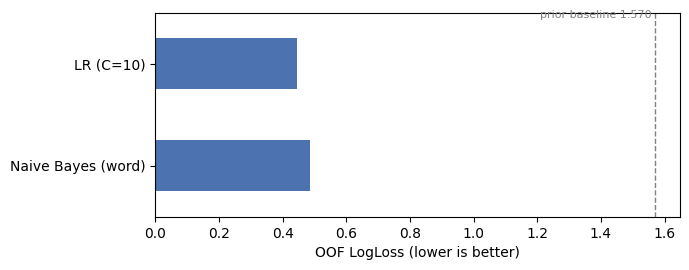

In [8]:
res = pd.DataFrame(results).T.sort_values('OOF LogLoss')
display(res.round(4))

ax = res['OOF LogLoss'].plot.barh(color='#4C72B0', figsize=(7, 2.8))
ax.axvline(1.570, color='gray', ls='--', lw=1); ax.text(1.56, -0.45, 'prior baseline 1.570', ha='right', fontsize=8, color='gray')
ax.set_xlabel('OOF LogLoss (lower is better)'); ax.invert_yaxis(); plt.tight_layout(); plt.show()

**해석**
- 두 모델 모두 기준선(1.57)보다 훨씬 낮은지 → 문체만으로 작가 구분이 가능한지 확인
- LR과 NB 중 LogLoss가 낮은 쪽이 베이스라인 대표 모델
- **131자 이상 문장의 LogLoss가 전체보다 낮다면** → 실제 test(긴 글) 점수는 OOF보다 좋게 나올 가능성이 큼

## 4. 결과 분석 (LR 기준)
### 4-1. 문장 길이별 성능

,문장 수,LogLoss,Accuracy,test 문장 비율
~50,9522,0.743,0.726,0.000
50~100,14034,0.553,0.801,0.000
100~200,14111,0.411,0.857,0.137
200~400,7853,0.285,0.910,0.393
400~,9219,0.168,0.956,0.469


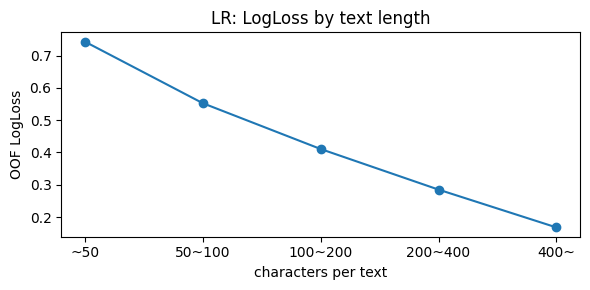

In [9]:
bins = [0, 50, 100, 200, 400, np.inf]
labels = ['~50', '50~100', '100~200', '200~400', '400~']
length_bin = pd.cut(train['text'].str.len(), bins=bins, labels=labels)

by_len = pd.DataFrame({
    '문장 수': length_bin.value_counts().reindex(labels),
    'LogLoss': [log_loss(y[length_bin == b], oof_lr[length_bin == b], labels=range(5)) for b in labels],
    'Accuracy': [accuracy_score(y[length_bin == b], oof_lr[length_bin == b].argmax(1)) for b in labels],
}, index=labels)
by_len['test 문장 비율'] = pd.cut(test['text'].str.len(), bins=bins, labels=labels).value_counts(normalize=True).reindex(labels)
display(by_len.round(3))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(labels, by_len['LogLoss'], marker='o')
ax.set_xlabel('characters per text'); ax.set_ylabel('OOF LogLoss'); ax.set_title('LR: LogLoss by text length')
plt.tight_layout(); plt.show()

- 문장이 길수록 LogLoss가 뚜렷하게 낮아짐 (50자 이하 짧은 대사가 가장 어려움)
- test는 짧은 문장이 거의 없고 200자 이상이 대부분 → **OOF 점수는 test 성능을 보수적으로(나쁘게) 추정**한 것
- 개선 아이디어: 짧은 문장은 정보가 적으니 **확률을 덜 확신하게** 만드는 후처리, 또는 긴 글을 잘 다루는 사전학습 모델

### 4-2. 작가별 혼동 행렬

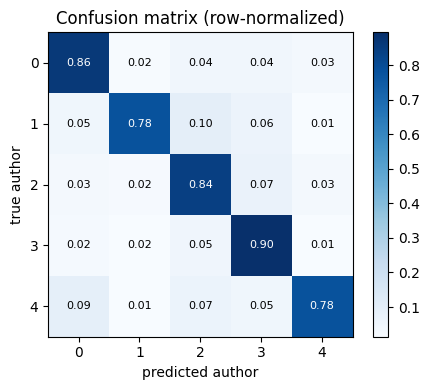

,LogLoss,Recall
author 0,0.399,0.862
author 1,0.658,0.780
author 2,0.454,0.841
author 3,0.305,0.895
author 4,0.588,0.780


In [10]:
cm = confusion_matrix(y, oof_lr.argmax(1), normalize='true')
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(cm, cmap='Blues')
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if cm[i, j] > .5 else 'black')
ax.set_xlabel('predicted author'); ax.set_ylabel('true author'); ax.set_title('Confusion matrix (row-normalized)')
plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.show()

per_author = pd.DataFrame({
    'LogLoss': [log_loss(y[y == a], oof_lr[y == a], labels=range(5)) for a in range(5)],
    'Recall': np.diag(cm),
}, index=[f'author {a}' for a in range(5)])
display(per_author.round(3))

- 대각선(맞힌 비율)과 가장 큰 비대각 칸(가장 많이 헷갈린 작가 쌍)을 확인
- 문장 수가 적은 작가(1, 4)의 재현율이 낮은지, 특정 작가 쌍끼리 많이 섞이는지 → 개선 단계에서 집중할 지점

## 5. 제출 파일 생성 (LR, 전체 train으로 재학습)

In [11]:
pred = LogisticRegression(C=BEST_C, max_iter=2000).fit(X_all, y).predict_proba(T_all)

sub = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')
sub[['0', '1', '2', '3', '4']] = pred
sub.to_csv(f'{DATA_DIR}/submission_baseline.csv', index=False)
print('저장:', f'{DATA_DIR}/submission_baseline.csv')
display(sub.head())

저장: /content/drive/MyDrive/ESAA_OB/OB_data/Project(2)/submission_baseline.csv


,index,0,1,2,3,4
0,0,0.124289,0.432824,0.395924,0.043792,0.003171
1,1,0.076947,0.882741,0.000991,0.031334,0.007988
2,2,0.993337,0.003852,0.000751,0.001467,0.000592
3,3,0.005658,0.000052,0.982148,0.000477,0.011666
4,4,0.980320,0.008001,0.002883,0.007598,0.001198


## 6. 정리 및 개선 방향

**베이스라인 결과**
1. 벡터화: 단어(1~2gram, 문장부호 토큰 포함) + 문자(2~5gram) TF-IDF, `sublinear_tf=True`
2. 문장부호를 토큰으로 살린 설정이 점수를 가장 크게 개선 (fold1 0.494 → 0.465) → 전처리 단계에서 문장부호를 지우지 않은 판단이 맞았음
3. LR / NB 5-fold OOF LogLoss: LR 0.446 (정확도 84.4%) / NB 0.485 (정확도 83.7%) → LR을 베이스라인 대표 모델로 선정. test와 길이가 비슷한 131자 이상 문장만 보면 LR LogLoss 0.275
4. 긴 문장일수록 성능이 좋아짐 → test(긴 글 위주) 점수는 OOF보다 좋을 것으로 예상

**다음 단계 (성능 향상 · 후처리)**
- 하이퍼파라미터 튜닝: LR `C`, NB `alpha`, 문자 n-gram 범위·`min_df`
- 다른 모델 추가 후 앙상블 (Linear SVM, NB-LR 등)
- 사전학습 언어모델(RoBERTa 등) 미세조정 후 TF-IDF 모델과 앙상블
- 확률 보정 후처리: 확률이 0/1에 너무 붙지 않게 클리핑·온도 조정 → LogLoss 직접 개선